In [2]:
import mglearn
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import joblib
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

In [3]:
os.getcwd()

'd:\\NCC-GCSP\\1st sem\\ML\\project\\Term_project'

In [4]:
data = pd.read_csv("./data/METABRIC_RNA_Mutation.csv")

clinical_documented_cols = data.columns[:31].tolist()
mutation_cols = [c for c in data.columns if c.lower().endswith("_mut")]
expression_cols = [
    c for c in data.columns[31:]
    if c not in mutation_cols
]

C:\Users\ASUS\AppData\Local\Temp\ipykernel_28996\1510743806.py:1: DtypeWarning: Columns (678,688,690,692) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("./data/METABRIC_RNA_Mutation.csv")


In [5]:
from sklearn.model_selection import train_test_split 

In [6]:
data["surv"] = np.where(data["overall_survival"] == 1, 0, 1)
## select the binary outcome
Y = data["surv"]

## Clinical Variables selection
### exclude tumor stage
### include age_at_diagnosis, nottingham_prognostic_index categorical, pam50_and_claudin, er_status, her2_status, pr_status


### Convert npt to dummy variables

In [7]:
npi_cat = pd.cut(
    data["nottingham_prognostic_index"],
    bins=[-np.inf, 2.4, 3.4, 4.4, 5.4, np.inf],
    labels=["excellent", "good", "moderate_1", "moderate_2", "poor"],
    right=True,
)
npi_dummies = pd.get_dummies(npi_cat, prefix="npi", dtype=int)

### Convert status to binary variables

In [8]:
data[["er_status", "pr_status", "her2_status"]] = data[["er_status", "pr_status", "her2_status"]].replace({"Negative": 0, "Positive": 1})
selected_clinical = ["age_at_diagnosis", "er_status", "pr_status", "her2_status"]

C:\Users\ASUS\AppData\Local\Temp\ipykernel_28996\1556225271.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data[["er_status", "pr_status", "her2_status"]] = data[["er_status", "pr_status", "her2_status"]].replace({"Negative": 0, "Positive": 1})


### Choosing columns and splitting data

In [9]:
## combine the selected clinical variables and NPI dummies into a single dataframe
X = pd.concat([data[selected_clinical], npi_dummies], axis=1)
## split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, random_state=0)

In [10]:
scaler = MinMaxScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[["age_at_diagnosis"]] = scaler.fit_transform(X_train[["age_at_diagnosis"]])  # learn min/max from train
X_test[["age_at_diagnosis"]] = scaler.transform(X_test[["age_at_diagnosis"]])        # reuse train min/max

### Logistic 

In [11]:
## fit logistic regression model
logistic_clinical = LogisticRegression(penalty= None).fit(X_train, y_train)


#### Mean accuracy

In [12]:
print('Mean Training Accuracy :',logistic_clinical.score(X_train, y_train))
print('Mean Test Accuracy :',logistic_clinical.score(X_test, y_test))

Mean Training Accuracy : 0.657563025210084
Mean Test Accuracy : 0.7100840336134454


#### Ridge regression

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = {}
for C in C_values:
    model = LogisticRegression(penalty='l1', C=C, solver='liblinear', max_iter=10000)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    results[C] = scores
    print(f"C={C:<7} | fold accuracies: {scores.round(3)} | mean: {scores.mean():.3f}")

best_C = max(results, key=lambda c: results[c].mean())
print("Best C by mean CV accuracy:", best_C)

C=0.001   | fold accuracies: [0.5 0.5 0.5 0.5 0.5] | mean: 0.500
C=0.01    | fold accuracies: [0.5 0.5 0.5 0.5 0.5] | mean: 0.500
C=0.1     | fold accuracies: [0.696 0.671 0.659 0.748 0.676] | mean: 0.690
C=1       | fold accuracies: [0.694 0.656 0.673 0.745 0.696] | mean: 0.693
C=10      | fold accuracies: [0.694 0.655 0.675 0.746 0.697] | mean: 0.693
C=100     | fold accuracies: [0.694 0.655 0.675 0.746 0.697] | mean: 0.693
Best C by mean CV accuracy: 100


In [14]:
logistic_clinical_l1 = LogisticRegression(penalty='l1', C=best_C, solver='liblinear', max_iter=10000).fit(X_train, y_train)
print('Mean Training Accuracy :',logistic_clinical_l1.score(X_train, y_train))
print('Mean Test Accuracy :',logistic_clinical_l1.score(X_test, y_test))

Mean Training Accuracy : 0.657563025210084
Mean Test Accuracy : 0.7100840336134454


In [15]:
y_prob = logistic_clinical_l1.predict_proba(X_test)[:, 1]   # probability of the positive class
auc = roc_auc_score(y_test, y_prob)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.748


### Lasso regression

### Using cross-validation to select best C

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = {}
for C in C_values:
    model = LogisticRegression(penalty='l2', C=C, max_iter=2000)
    scores = cross_val_score(model, X_train, y_train, cv=cv)
    results[C] = scores
    print(f"C={C:<7} | fold accuracies: {scores.round(3)} | mean: {scores.mean():.3f}")

best_C = max(results, key=lambda c: results[c].mean())
print("Best C by mean CV accuracy:", best_C)

C=0.001   | fold accuracies: [0.573 0.573 0.573 0.572 0.575] | mean: 0.574
C=0.01    | fold accuracies: [0.573 0.573 0.573 0.572 0.575] | mean: 0.574
C=0.1     | fold accuracies: [0.643 0.619 0.633 0.674 0.639] | mean: 0.641
C=1       | fold accuracies: [0.654 0.612 0.633 0.695 0.656] | mean: 0.650
C=10      | fold accuracies: [0.657 0.605 0.64  0.688 0.656] | mean: 0.649
C=100     | fold accuracies: [0.657 0.608 0.636 0.688 0.653] | mean: 0.648
Best C by mean CV accuracy: 1


#### so we choose c = 1 for Lasso regression

In [17]:
logistic_clinical_l2 = LogisticRegression(penalty='l2', C=best_C, max_iter=2000).fit(X_train, y_train)
print('Mean Training Accuracy :',logistic_clinical_l2.score(X_train, y_train))
print('Mean Test Accuracy :',logistic_clinical_l2.score(X_test, y_test))

Mean Training Accuracy : 0.657563025210084
Mean Test Accuracy : 0.7100840336134454


### Decision tree   

### Pre-puring decision tree

### Random forest

n_estimators= 10 | train: 0.959 | validation: 0.628
n_estimators= 20 | train: 0.978 | validation: 0.643
n_estimators= 30 | train: 0.987 | validation: 0.641
n_estimators= 40 | train: 0.988 | validation: 0.639
n_estimators= 50 | train: 0.992 | validation: 0.647
n_estimators= 60 | train: 0.993 | validation: 0.647
n_estimators= 70 | train: 0.992 | validation: 0.647
n_estimators= 80 | train: 0.992 | validation: 0.647
n_estimators= 90 | train: 0.992 | validation: 0.658
n_estimators=100 | train: 0.993 | validation: 0.649


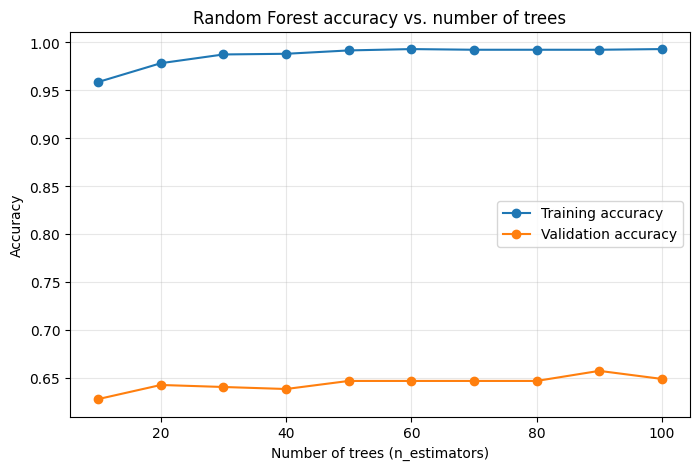

In [18]:
n_trees = range(10, 101, 10)   
train_acc = []
test_acc = []

for n in n_trees:
    forest = RandomForestClassifier(n_estimators=n, random_state=2)
    forest.fit(X_train, y_train)
    train_acc.append(forest.score(X_train, y_train))
    test_acc.append(forest.score(X_test, y_test))
    print(f"n_estimators={n:3d} | train: {train_acc[-1]:.3f} | validation: {test_acc[-1]:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(n_trees, train_acc, marker="o", label="Training accuracy")
plt.plot(n_trees, test_acc, marker="o", label="Validation accuracy")
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Accuracy")
plt.title("Random Forest accuracy vs. number of trees")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
### choose 90 trees for the final model
forest_90 = RandomForestClassifier(n_estimators=90, random_state=2) 
forest_90.fit(X_train, y_train) 
print('Training Set Accuracy :',forest_90.score(X_train, y_train))
print('Validation Set Accuracy :',forest_90.score(X_test, y_test))

Training Set Accuracy : 0.992296918767507
Validation Set Accuracy : 0.657563025210084


In [20]:
os.makedirs("models", exist_ok=True)
model_path = "models/rf_grid_search.joblib"

if os.path.exists(model_path):
    grid_search = joblib.load(model_path)          
else:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    rf = RandomForestClassifier(random_state=123)

    param_grid = {
        "max_depth": [5, 10, 15, None],
        "min_samples_leaf": [2, 5, 10, 20],
        "min_samples_split": [5, 10, 20],
        "n_estimators": range(10, 101, 10),
    }

    grid_search = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        n_jobs=-1,                                 
    )
    grid_search.fit(X_train, y_train)
    joblib.dump(grid_search, model_path) 

In [21]:
model_path = "models/rf_grid_search.joblib"

if os.path.exists(model_path):
    grid_search = joblib.load(model_path)          
else:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    rf = RandomForestClassifier(random_state=123)

    param_grid = {
        "max_depth": [5, 10, 15, None],
        "min_samples_leaf": [2, 5, 10, 20],
        "min_samples_split": [5, 10, 20],
        "n_estimators": range(10, 101, 10),
    }

    grid_search = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        n_jobs=-1,                                 
    )
    grid_search.fit(X_train, y_train)
    joblib.dump(grid_search, model_path) 

In [22]:
# final random forest model with best parameters
rf_clinical = grid_search.best_estimator_
print("Training accuracy:", rf_clinical.score(X_train, y_train))
print("Test accuracy:", rf_clinical.score(X_test, y_test))

Training accuracy: 0.6827731092436975
Test accuracy: 0.707983193277311


### SVM

In [23]:
svc_path = "models/svc_grid_search.joblib"

if os.path.exists(svc_path):
    grid_search_svc = joblib.load(svc_path)
else:
    param_grid = {
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "gamma": [0.001, 0.01, 0.1, 1, 10, 100],
    }

    grid_search_svc = GridSearchCV(
        SVC(), param_grid, cv=5, scoring="roc_auc",
        return_train_score=True                     
    )
    grid_search_svc.fit(X_train, y_train)
    joblib.dump(grid_search_svc, svc_path)

In [24]:
print("Best parameters:", grid_search_svc.best_params_)

Best parameters: {'C': 100, 'gamma': 0.01}


In [25]:
svc_clinical = grid_search_svc.best_estimator_
y_score = svc_clinical.decision_function(X_test)
auc = roc_auc_score(y_test, y_score)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.750


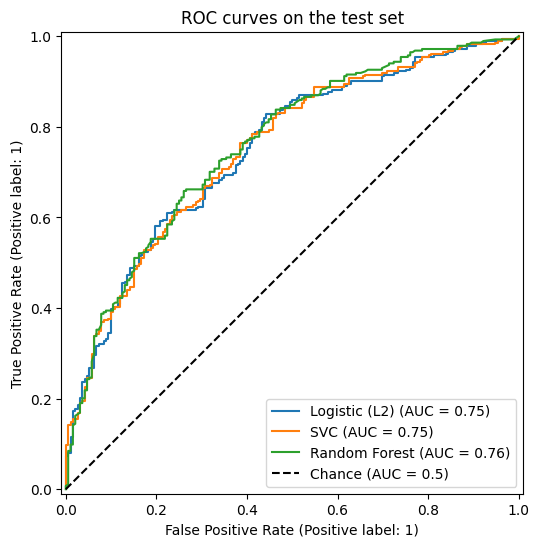

In [26]:
models = {
    "Logistic (L2)": logistic_clinical_l2,
    "SVC": svc_clinical,
    "Random Forest": rf_clinical,
}

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)

ax.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.5)")
ax.legend(loc="lower right")
ax.set_title("ROC curves on the test set")
plt.show()

## Expression data

In [27]:
X_expressions = data[expression_cols]
## split the expression data into training and testing sets

X_expression_train, X_expression_test = train_test_split(X_expressions, random_state=0)

### Logistic regression

In [28]:
logistic_expression = LogisticRegression(penalty=None, max_iter=10000).fit(X_expression_train, y_train)

In [29]:
print('Mean Training Accuracy :',logistic_expression.score(X_expression_train, y_train))
print('Mean Test Accuracy :',logistic_expression.score(X_expression_test, y_test))

Mean Training Accuracy : 0.8291316526610645
Mean Test Accuracy : 0.6302521008403361


In [30]:
y_prob = logistic_expression.predict_proba(X_expression_test)[:, 1]   # probability of the positive class
auc = roc_auc_score(y_test, y_prob)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.627


#### Ridge regression

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = {}
for C in C_values:
    model = LogisticRegression(penalty='l1', C=C, solver='liblinear', max_iter=10000)
    scores = cross_val_score(model, X_expression_train, y_train, cv=cv, scoring="roc_auc")
    results[C] = scores
    print(f"C={C:<7} | fold accuracies: {scores.round(3)} | mean: {scores.mean():.3f}")

best_C = max(results, key=lambda c: results[c].mean())
print("Best C by mean CV accuracy:", best_C)

C=0.001   | fold accuracies: [0.5 0.5 0.5 0.5 0.5] | mean: 0.500
C=0.01    | fold accuracies: [0.618 0.656 0.615 0.643 0.6  ] | mean: 0.626
C=0.1     | fold accuracies: [0.621 0.637 0.613 0.65  0.625] | mean: 0.629
C=1       | fold accuracies: [0.571 0.555 0.578 0.614 0.608] | mean: 0.585
C=10      | fold accuracies: [0.543 0.531 0.56  0.596 0.603] | mean: 0.566
C=100     | fold accuracies: [0.541 0.53  0.556 0.592 0.602] | mean: 0.564
Best C by mean CV accuracy: 0.1


In [32]:
logistic_expression_l1 = LogisticRegression(penalty='l1', C=best_C, solver='liblinear', max_iter=10000).fit(X_expression_train, y_train)
print('Mean Training Accuracy :',logistic_expression_l1.score(X_expression_train, y_train))
print('Mean Test Accuracy :',logistic_expression_l1.score(X_expression_test, y_test))

Mean Training Accuracy : 0.7619047619047619
Mean Test Accuracy : 0.6701680672268907


In [33]:
y_prob = logistic_expression_l1.predict_proba(X_expression_test)[:, 1]   # probability of the positive class
auc = roc_auc_score(y_test, y_prob)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.706


### Lasso regression

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = {}
for C in C_values:
    model = LogisticRegression(penalty='l2', C=C, max_iter=10000)
    scores = cross_val_score(model, X_expression_train, y_train, cv=cv, scoring="roc_auc")
    results[C] = scores
    print(f"C={C:<7} | fold accuracies: {scores.round(3)} | mean: {scores.mean():.3f}")

best_C = max(results, key=lambda c: results[c].mean())
print("Best C by mean CV accuracy:", best_C)

C=0.001   | fold accuracies: [0.634 0.726 0.648 0.655 0.667] | mean: 0.666
C=0.01    | fold accuracies: [0.635 0.645 0.616 0.658 0.647] | mean: 0.641
C=0.1     | fold accuracies: [0.592 0.574 0.582 0.63  0.614] | mean: 0.598
C=1       | fold accuracies: [0.558 0.543 0.565 0.603 0.604] | mean: 0.575
C=10      | fold accuracies: [0.543 0.531 0.558 0.595 0.602] | mean: 0.566
C=100     | fold accuracies: [0.541 0.53  0.556 0.591 0.603] | mean: 0.564
Best C by mean CV accuracy: 0.001


In [35]:
logistic_expression_l2 = LogisticRegression(penalty='l2', C=best_C, max_iter=10000).fit(X_expression_train, y_train)
print('Mean Training Accuracy :',logistic_expression_l2.score(X_expression_train, y_train))
print('Mean Test Accuracy :',logistic_expression_l2.score(X_expression_test, y_test))

Mean Training Accuracy : 0.7212885154061625
Mean Test Accuracy : 0.6764705882352942


In [36]:
y_prob = logistic_expression_l2.predict_proba(X_expression_test)[:, 1]   # probability of the positive class
auc = roc_auc_score(y_test, y_prob)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.709


### in high dimension dataset lasso will increase the prediction accuracy

#### Random forest

In [37]:
rf_ex_path = "models/rf__ex_grid_search.joblib"

if os.path.exists(rf_ex_path):
    grid_search = joblib.load(rf_ex_path)          
else:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    rf = RandomForestClassifier(random_state=123)

    param_grid = {
        "max_depth": [5, 10, 15],
        "min_samples_leaf": [2, 5, 10, 20],
        "min_samples_split": [5, 10, 20],
        "n_estimators": range(10, 101, 10),
    }

    grid_search = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        n_jobs=-1,                                 
    )
    grid_search.fit(X_expression_train, y_train)
    joblib.dump(grid_search, rf_ex_path) 

In [38]:
print("Best parameters:", grid_search.best_params_)

Best parameters: {'max_depth': 15, 'min_samples_leaf': 10, 'min_samples_split': 5, 'n_estimators': 60}


In [39]:
rf_expression = grid_search.best_estimator_    
print("Training accuracy:", rf_expression.score(X_expression_train, y_train))
print("Test accuracy:", rf_expression.score(X_expression_test, y_test))

Training accuracy: 0.9544817927170869
Test accuracy: 0.6491596638655462


In [40]:
y_prob = rf_expression.predict_proba(X_expression_test)[:, 1]   # probability of the positive class
auc = roc_auc_score(y_test, y_prob)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.704


#### SVM

In [41]:
svc_ex_path = "models/svc_ex_grid_search.joblib"

if os.path.exists(svc_ex_path):
    grid_search_svc = joblib.load(svc_ex_path)
else:
    param_grid = {
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "gamma": [0.001, 0.01, 0.1, 1, 10, 100],
    }

    grid_search_svc = GridSearchCV(
        SVC(), param_grid, cv=5, scoring="roc_auc",
        return_train_score=True                     
    )
    grid_search_svc.fit(X_expression_train, y_train)
    joblib.dump(grid_search_svc, svc_ex_path)

In [42]:
print("Best parameters:", grid_search_svc.best_params_)

Best parameters: {'C': 1, 'gamma': 0.001}


In [43]:
print("Best ROC-AUC score:", grid_search_svc.best_score_)
print("Test set score:", grid_search_svc.score(X_expression_test, y_test))

Best ROC-AUC score: 0.6752074959703286
Test set score: 0.7214275234741783


In [44]:
svc_expression = grid_search_svc.best_estimator_
y_score = svc_expression.decision_function(X_expression_test)
auc = roc_auc_score(y_test, y_score)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.721


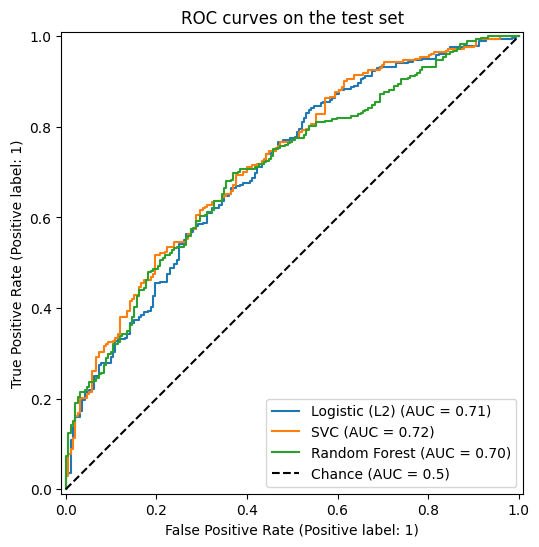

In [45]:
models = {
    "Logistic (L2)": logistic_expression_l2,
    "SVC": svc_expression,
    "Random Forest": rf_expression,
}

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_expression_test, y_test, ax=ax, name=name)

ax.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.5)")
ax.legend(loc="lower right")
ax.set_title("ROC curves on the test set")
plt.show()

## Combining clinical and expression

In [46]:
X_combined_train = pd.concat([X_train, X_expression_train], axis=1)
X_combined_test = pd.concat([X_test, X_expression_test], axis=1)

In [47]:
logistic_clinical_expression = LogisticRegression(penalty=None, max_iter=10000).fit(X_combined_train, y_train)

print('Mean Training Accuracy :',logistic_clinical_expression.score(X_combined_train, y_train))
print('Mean Test Accuracy :',logistic_clinical_expression.score(X_combined_test, y_test))

Mean Training Accuracy : 0.8648459383753502
Mean Test Accuracy : 0.6407563025210085


#### Ridge

In [48]:
# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
# C_values = [0.001, 0.01, 0.1, 1, 10, 100]

# results = {}
# for C in C_values:
#     model = LogisticRegression(penalty='l1', C=C, solver='liblinear', max_iter=10000)
#     scores = cross_val_score(model, X_combined_train, y_train, cv=cv, scoring="roc_auc")
#     results[C] = scores
#     print(f"C={C:<7} | fold accuracies: {scores.round(3)} | mean: {scores.mean():.3f}")

# best_C = max(results, key=lambda c: results[c].mean())
# print("Best C by mean CV accuracy:", best_C)

C=0.001   | fold accuracies: [0.5 0.5 0.5 0.5 0.5] | mean: 0.500
C=0.01    | fold accuracies: [0.618 0.656 0.615 0.643 0.6  ] | mean: 0.626
C=0.1     | fold accuracies: [0.647 0.665 0.634 0.677 0.637] | mean: 0.652
C=1       | fold accuracies: [0.636 0.596 0.609 0.655 0.637] | mean: 0.626
C=10      | fold accuracies: [0.601 0.567 0.589 0.633 0.618] | mean: 0.602
C=100     | fold accuracies: [0.604 0.564 0.591 0.624 0.609] | mean: 0.598
Best C by mean CV accuracy: 0.1


In [49]:
# logistic_combined_l1 = LogisticRegression(penalty='l1', C=best_C, solver='liblinear', max_iter=10000).fit(X_combined_train, y_train)
# print('Mean Training Accuracy :',logistic_combined_l1.score(X_combined_train, y_train))
# print('Mean Test Accuracy :',logistic_combined_l1.score(X_combined_test, y_test))

In [ ]:
# y_prob = logistic_combined_l1.predict_proba(X_combined_test)[:, 1]   # probability of the positive class
# auc = roc_auc_score(y_test, y_prob)
# print(f"Test ROC-AUC: {auc:.3f}")

NameError: name 'logistic_combined_l1' is not defined

### Lasso regression

In [52]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = {}
for C in C_values:
    model = LogisticRegression(penalty='l2', C=C, max_iter=10000)
    scores = cross_val_score(model, X_combined_train, y_train, cv=cv, scoring="roc_auc")
    results[C] = scores
    print(f"C={C:<7} | fold accuracies: {scores.round(3)} | mean: {scores.mean():.3f}")

best_C = max(results, key=lambda c: results[c].mean())
print("Best C by mean CV accuracy:", best_C)

C=0.001   | fold accuracies: [0.637 0.727 0.65  0.658 0.668] | mean: 0.668
C=0.01    | fold accuracies: [0.646 0.652 0.622 0.667 0.652] | mean: 0.648
C=0.1     | fold accuracies: [0.615 0.59  0.597 0.651 0.622] | mean: 0.615
C=1       | fold accuracies: [0.603 0.569 0.586 0.635 0.618] | mean: 0.602
C=10      | fold accuracies: [0.594 0.564 0.585 0.63  0.622] | mean: 0.599
C=100     | fold accuracies: [0.594 0.556 0.587 0.63  0.609] | mean: 0.595
Best C by mean CV accuracy: 0.001


In [54]:
logistic_combined_l2 = LogisticRegression(penalty='l2', C=best_C, max_iter=10000).fit(X_combined_train, y_train)
print('Mean Training Accuracy :',logistic_combined_l2.score(X_combined_train, y_train))
print('Mean Test Accuracy :',logistic_combined_l2.score(X_combined_test, y_test))

Mean Training Accuracy : 0.726890756302521
Mean Test Accuracy : 0.680672268907563


In [55]:
y_prob = logistic_combined_l2.predict_proba(X_combined_test)[:, 1]   # probability of the positive class
auc = roc_auc_score(y_test, y_prob)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.712


#### Random forest

In [56]:
rf_combined_path = "models/rf_combined_grid_search.joblib"

if os.path.exists(rf_combined_path):
    grid_search = joblib.load(rf_combined_path)          
else:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
    rf = RandomForestClassifier(random_state=123)

    param_grid = {
        "max_depth": [5, 10, 15],
        "min_samples_leaf": [2, 5, 10, 20],
        "min_samples_split": [5, 10, 20],
        "n_estimators": range(10, 101, 10),
    }

    grid_search = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        n_jobs=-1,                                 
    )
    grid_search.fit(X_combined_train, y_train)
    joblib.dump(grid_search, rf_combined_path) 

In [57]:
print("Best parameters:", grid_search.best_params_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 20, 'n_estimators': 100}


In [58]:
rf_combined = grid_search.best_estimator_    
print("Training accuracy:", rf_combined.score(X_combined_train, y_train))
print("Test accuracy:", rf_combined.score(X_combined_test, y_test))

Training accuracy: 0.9677871148459384
Test accuracy: 0.6680672268907563


In [59]:
y_prob = rf_combined.predict_proba(X_combined_test)[:, 1]   # probability of the positive class
auc = roc_auc_score(y_test, y_prob)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.746


### SVM

In [60]:
svc_combined_path = "models/svc_combined_grid_search.joblib"

if os.path.exists(svc_combined_path):
    grid_search_svc = joblib.load(svc_combined_path)
else:
    param_grid = {
        "C": [0.001, 0.01, 0.1, 1, 10, 100],
        "gamma": [0.001, 0.01, 0.1, 1, 10, 100],
    }

    grid_search_svc = GridSearchCV(
        SVC(), param_grid, cv=5, scoring="roc_auc",
        return_train_score=True                     
    )
    grid_search_svc.fit(X_combined_train, y_train)
    joblib.dump(grid_search_svc, svc_combined_path)

In [61]:
print("Best parameters:", grid_search_svc.best_params_)

Best parameters: {'C': 1, 'gamma': 0.001}


In [62]:
print("Best ROC-AUC score:", grid_search_svc.best_score_)
print("Test set score:", grid_search_svc.score(X_combined_test, y_test))

Best ROC-AUC score: 0.6777717894234588


Test set score: 0.7262507335680751


In [63]:
svc_combined = grid_search_svc.best_estimator_
y_score = svc_combined.decision_function(X_combined_test)
auc = roc_auc_score(y_test, y_score)
print(f"Test ROC-AUC: {auc:.3f}")

Test ROC-AUC: 0.726


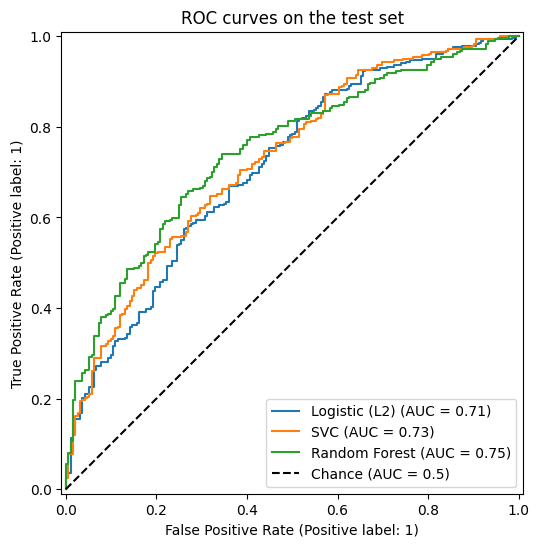

In [64]:
models = {
    "Logistic (L2)": logistic_combined_l2,
    "SVC": svc_combined,
    "Random Forest": rf_combined,
}

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_combined_test, y_test, ax=ax, name=name)

ax.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.5)")
ax.legend(loc="lower right")
ax.set_title("ROC curves on the test set")
plt.show()

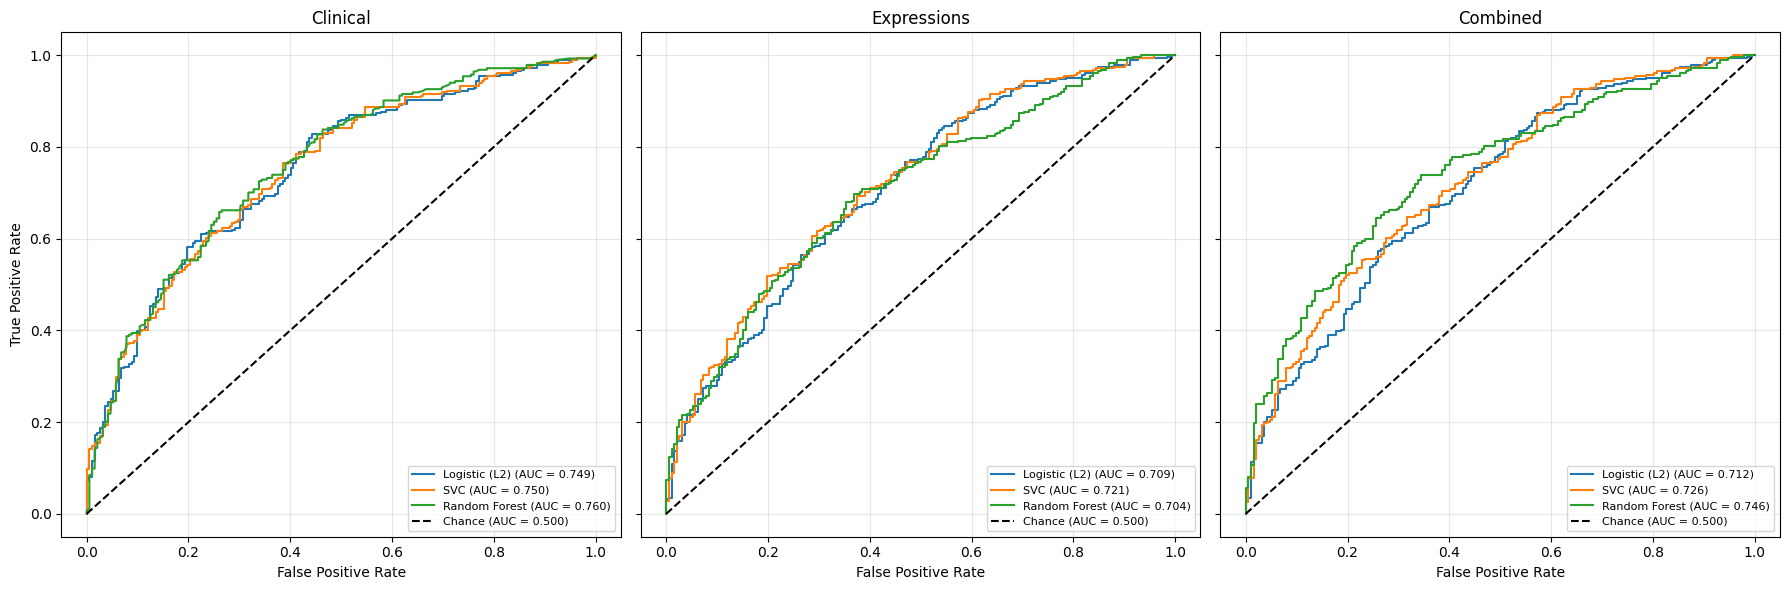

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

def get_score(model, X):
    """Return continuous scores for ROC, aligning X to the columns the model was fit on."""
    # reorder/select test columns to exactly match training columns (fixes name/order errors)
    if isinstance(X, pd.DataFrame) and hasattr(model, "feature_names_in_"):
        X = X[list(model.feature_names_in_)]

    # prefer decision_function (logistic, SVC); fall back to predict_proba (random forest)
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def plot_roc_facets(facets, y, figsize=(18, 6)):
    fig, axes = plt.subplots(1, len(facets), figsize=figsize, sharey=True)
    axes = [axes] if len(facets) == 1 else axes

    for ax, (title, (models, X)) in zip(axes, facets.items()):
        for name, model in models.items():
            try:
                score = get_score(model, X)
            except Exception as e:
                raise RuntimeError(f"Failed on facet '{title}', model '{name}': {e}") from e

            fpr, tpr, _ = roc_curve(y, score)
            auc = roc_auc_score(y, score)
            ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

        ax.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.500)")
        ax.set(title=title, xlabel="False Positive Rate")
        ax.legend(loc="lower right", fontsize=8)
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("True Positive Rate")
    plt.tight_layout()
    return fig


facets = {
    "Clinical": (
        {"Logistic (L2)": logistic_clinical_l2, "SVC": svc_clinical, "Random Forest": rf_clinical},
        X_test,
    ),
    "Expressions": (
        {"Logistic (L2)": logistic_expression_l2, "SVC": svc_expression, "Random Forest": rf_expression},
        X_expression_test,
    ),
    "Combined": (
        {"Logistic (L2)": logistic_combined_l2, "SVC": svc_combined, "Random Forest": rf_combined},
        X_combined_test,
    ),
}

fig = plot_roc_facets(facets, y_test)
fig.savefig("roc_facets.png", dpi=300, bbox_inches="tight")
plt.show()

      Features          Model  Train   Test    Gap
0     Clinical  Logistic (L2)  0.658  0.710 -0.053
1     Clinical            SVC  0.663  0.704 -0.041
2     Clinical  Random Forest  0.683  0.708 -0.025
3  Expressions  Logistic (L2)  0.721  0.676  0.045
4  Expressions            SVC  0.803  0.672  0.131
5  Expressions  Random Forest  0.954  0.649  0.305
6     Combined  Logistic (L2)  0.727  0.681  0.046
7     Combined            SVC  0.809  0.668  0.141
8     Combined  Random Forest  0.968  0.668  0.300


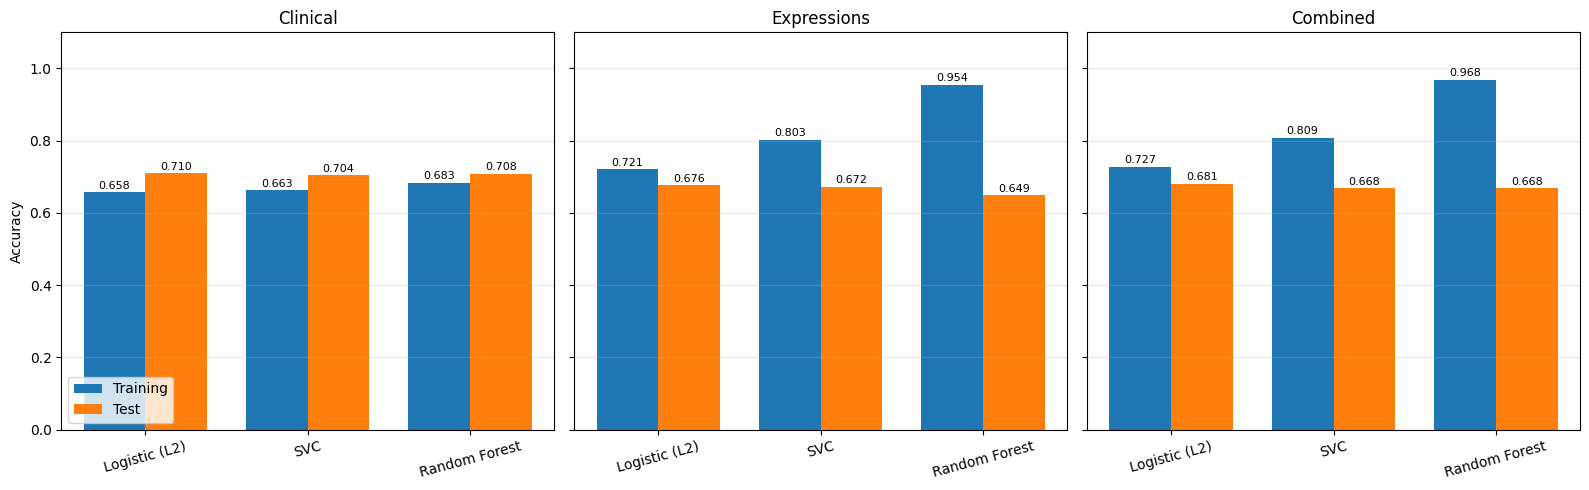

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

# (model, train features, test features) for each combination
runs = {
    ("Clinical", "Logistic (L2)"):    (logistic_clinical_l2,   X_train,             X_test),
    ("Clinical", "SVC"):              (svc_clinical,           X_train,             X_test),
    ("Clinical", "Random Forest"):    (rf_clinical,            X_train,             X_test),
    ("Expressions", "Logistic (L2)"): (logistic_expression_l2, X_expression_train,  X_expression_test),
    ("Expressions", "SVC"):           (svc_expression,         X_expression_train,  X_expression_test),
    ("Expressions", "Random Forest"): (rf_expression,          X_expression_train,  X_expression_test),
    ("Combined", "Logistic (L2)"):    (logistic_combined_l2,   X_combined_train,    X_combined_test),
    ("Combined", "SVC"):              (svc_combined,           X_combined_train,    X_combined_test),
    ("Combined", "Random Forest"):    (rf_combined,            X_combined_train,    X_combined_test),
}

rows = []
for (features, name), (model, Xtr, Xte) in runs.items():
    train_acc = model.score(Xtr, y_train)
    test_acc = model.score(Xte, y_test)
    rows.append({
        "Features": features,
        "Model": name,
        "Train": train_acc,
        "Test": test_acc,
        "Gap": train_acc - test_acc,
    })

scores = pd.DataFrame(rows)
print(scores.round(3))

# grouped bars: one panel per feature set
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (features, df) in zip(axes, scores.groupby("Features", sort=False)):
    x = range(len(df))
    w = 0.38
    ax.bar([i - w/2 for i in x], df["Train"], width=w, label="Training")
    ax.bar([i + w/2 for i in x], df["Test"], width=w, label="Test")
    for i, (tr, te) in enumerate(zip(df["Train"], df["Test"])):
        ax.text(i - w/2, tr + 0.01, f"{tr:.3f}", ha="center", fontsize=8)
        ax.text(i + w/2, te + 0.01, f"{te:.3f}", ha="center", fontsize=8)
    ax.set_xticks(list(x))
    ax.set_xticklabels(df["Model"], rotation=15)
    ax.set_title(features)
    ax.set_ylim(0, 1.1)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

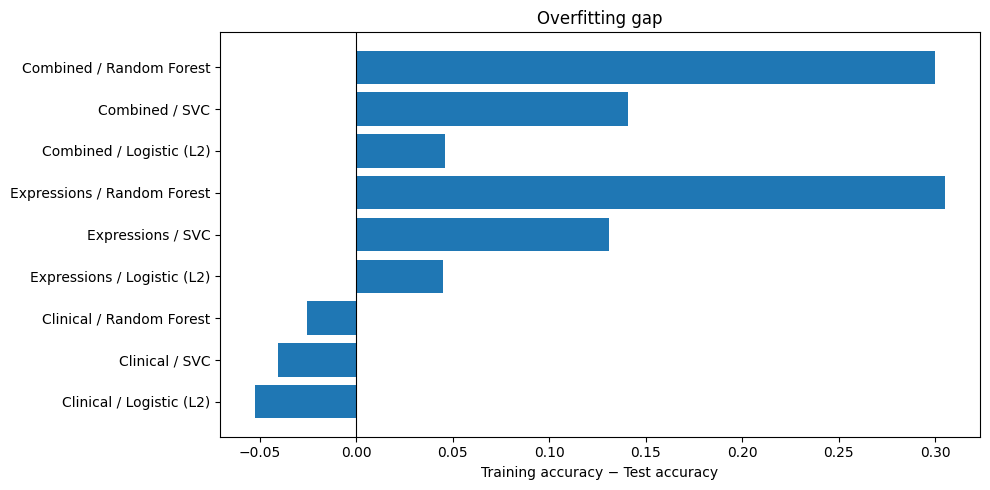

In [67]:
scores["Label"] = scores["Features"] + " / " + scores["Model"]

plt.figure(figsize=(10, 5))
plt.barh(scores["Label"], scores["Gap"])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Training accuracy − Test accuracy")
plt.title("Overfitting gap")
plt.tight_layout()
plt.show()

## Gene selection

In [ ]:
def bootstrap_gene_frequency(
    X,
    y,
    n_bootstraps=300,
    C=0.1,
    random_state=123
):
    """
    Estimate gene-selection frequency using bootstrap samples.
    X: training-fold DataFrame containing gene-expression features.
    y: binary outcome from the same training fold.
    """
    rng = np.random.default_rng(random_state)
    n = len(X)

    selection_counts = pd.Series(
        0, index=X.columns, dtype=int
    )

    for b in range(n_bootstraps):
        # Sample patients with replacement
        idx = rng.integers(0, n, size=n)
        X_boot = X.iloc[idx]
        y_boot = np.asarray(y)[idx]

        # Scaling is fitted only on this bootstrap sample
        # scaler = StandardScaler()
        # X_scaled = scaler.fit_transform(X_boot)

        model = LogisticRegression(
            penalty="l1",
            solver='liblinear', 
            max_iter=10000,
            C=C,
            random_state=random_state + b
        )
        model.fit(X_boot, y_boot)

        selected = np.abs(model.coef_[0]) > 1e-8
        selection_counts.loc[X.columns[selected]] += 1

    frequencies = selection_counts / n_bootstraps

    return frequencies.sort_values(ascending=False)

In [ ]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

# X_train and y_train must come from the initial train/test split.
# gene_cols must contain only the 489 gene-expression features.

X = X_expression_train.copy()
y = pd.Series(y_train, index=X.index).reset_index(drop=True)
X = X.reset_index(drop=True)

outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=123
)

C_grid = [0.001, 0.01, 0.1, 1, 10]
outer_results = []
fold_gene_lists = []

for fold, (tr_idx, val_idx) in enumerate(outer_cv.split(X, y), 1):
    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    # Tune L1 regularization using only this outer training fold
    tune_pipe = Pipeline([
        ("scale", StandardScaler()),
        ("l1", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=10000,
            random_state=123
        ))
    ])

    inner_cv = StratifiedKFold(
        n_splits=4, shuffle=True, random_state=fold
    )

    search = GridSearchCV(
        tune_pipe,
        {"l1__C": C_grid},
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_tr, y_tr)
    best_C = search.best_params_["l1__C"]

    # Bootstrap selection uses only outer training data
    freq = bootstrap_gene_frequency(
        X_tr,
        y_tr,
        n_bootstraps=300,
        C=best_C,
        random_state=1000 + fold
    )

    selected_genes = freq.head(15).index.tolist()
    fold_gene_lists.append(selected_genes)
    # Fit the final classifier on the selected genes
    final_model = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l2",
            C=1.0,
            max_iter=3000
        ))
    ])

    final_model.fit(X_tr[selected_genes], y_tr)
    val_prob = final_model.predict_proba(
        X_val[selected_genes]
    )[:, 1]

    auc = roc_auc_score(y_val, val_prob)

    outer_results.append({
        "fold": fold,
        "best_L1_C": best_C,
        "n_genes": len(selected_genes),
        "roc_auc": auc
    })

results_df = pd.DataFrame(outer_results)
print(results_df)
print("Mean outer CV AUC:", results_df["roc_auc"].mean())
print("SD outer CV AUC:", results_df["roc_auc"].std(ddof=1))

   fold  best_L1_C  n_genes   roc_auc
0     1        0.1       15  0.613055
1     2        0.1       15  0.566024
2     3        0.1       15  0.536485
3     4        0.1       15  0.614302
4     5        0.1       15  0.546160
Mean outer CV AUC: 0.5752050683047777
SD outer CV AUC: 0.03670237709769299
